In [1]:
%pip install -q fastai

Note: you may need to restart the kernel to use updated packages.


In [2]:
from pathlib import Path

path = Path("../../training_data")

In [3]:
from fastai.vision.all import *

files = get_image_files(path / "images")
files[0]

Path('../../training_data/images/default_mmrsagar_mMRS-BPB_12122023120517.jpg')

In [4]:
import numpy as np


# return the name of the parent folder
def label_func(fn: Path):
    return path / "binary_masks" / f"{fn.stem}.png"


dls = SegmentationDataLoaders.from_label_func(
    path,
    bs=1,
    fnames=files,
    label_func=label_func,
    codes=np.array(["Background", "Colony"]),
    item_tfms=Resize(2048),
)

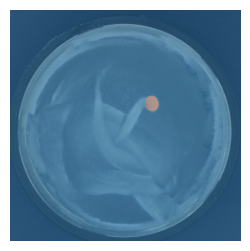

In [5]:
dls.show_batch()

In [6]:
learn = unet_learner(dls, resnet34)
learn.fine_tune(6)

epoch,train_loss,valid_loss,time


/opt/miniconda3/lib/python3.12/site-packages/fastai/learner.py:448: SyntaxWarning: invalid escape sequence '\R'
  e.args = [f"Custom classes or functions exported with your `Learner` not available in namespace.\Re-declare/import before loading:\n\t{e.args[0]}"]


RuntimeError: MPS backend out of memory (MPS allocated: 16.72 GB, other allocations: 356.58 MB, max allowed: 18.13 GB). Tried to allocate 1.55 GB on private pool. Use PYTORCH_MPS_HIGH_WATERMARK_RATIO=0.0 to disable upper limit for memory allocations (may cause system failure).

In [ ]:
learn.show_results()